# 4. Model evaluation dashboard

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, multilabel_confusion_matrix, roc_auc_score

ROOT = Path.cwd().resolve()
if not (ROOT / "artifacts").exists() and (ROOT.parent / "artifacts").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "artifacts"
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
required = [ARTIFACTS / "toxicity_word_char_tfidf.joblib", ARTIFACTS / "sms_spam_tfidf_logistic_regression.joblib", DATA / "toxicity_test.csv", DATA / "spam_test.csv"]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Run data preparation and model training first. Missing: " + ", ".join(missing))

tox_bundle = joblib.load(ARTIFACTS / "toxicity_word_char_tfidf.joblib")
spam_bundle = joblib.load(ARTIFACTS / "sms_spam_tfidf_logistic_regression.joblib")
tox_test = pd.read_csv(DATA / "toxicity_test.csv")
spam_test = pd.read_csv(DATA / "spam_test.csv")

## Toxicity model: overall metrics

In [2]:
X_tox = tox_bundle["features"].transform(tox_test["text"].fillna("").astype(str))
Y_tox = tox_test[LABELS].astype(int).to_numpy()
P_tox = tox_bundle["model"].predict_proba(X_tox)
thresholds = tox_bundle["thresholds"]
Y_tox_pred = np.column_stack([P_tox[:, i] >= thresholds[label] for i, label in enumerate(LABELS)]).astype(int)

tox_overall = pd.DataFrame([
    {"metric": "Subset accuracy (all 6 labels must match)", "value": accuracy_score(Y_tox, Y_tox_pred)},
    {"metric": "Hamming loss (lower is better)", "value": np.mean(Y_tox != Y_tox_pred)},
    {"metric": "Micro precision", "value": precision_score(Y_tox, Y_tox_pred, average="micro", zero_division=0)},
    {"metric": "Micro recall", "value": recall_score(Y_tox, Y_tox_pred, average="micro", zero_division=0)},
    {"metric": "Micro F1", "value": f1_score(Y_tox, Y_tox_pred, average="micro", zero_division=0)},
    {"metric": "Macro precision", "value": precision_score(Y_tox, Y_tox_pred, average="macro", zero_division=0)},
    {"metric": "Macro recall", "value": recall_score(Y_tox, Y_tox_pred, average="macro", zero_division=0)},
    {"metric": "Macro F1", "value": f1_score(Y_tox, Y_tox_pred, average="macro", zero_division=0)},
    {"metric": "Weighted F1", "value": f1_score(Y_tox, Y_tox_pred, average="weighted", zero_division=0)},
])
display(tox_overall.style.format({"value": "{:.4f}"}))

,metric,value
0,Subset accuracy (all 6 labels must match),0.9177
1,Hamming loss (lower is better),0.0176
2,Micro precision,0.7564
3,Micro recall,0.7767
4,Micro F1,0.7664
5,Macro precision,0.6370
6,Macro recall,0.6474
7,Macro F1,0.6327
8,Weighted F1,0.7693


## Toxicity model: per-label accuracy, precision, recall, F1

In [3]:
per_label_rows = []
for i, label in enumerate(LABELS):
    y_true = Y_tox[:, i]
    y_pred = Y_tox_pred[:, i]
    row = {
        "label": label,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "support_positive": int(y_true.sum()),
        "threshold": float(thresholds[label]),
    }
    try:
        row["roc_auc"] = roc_auc_score(y_true, P_tox[:, i])
    except ValueError:
        row["roc_auc"] = np.nan
    per_label_rows.append(row)
per_label = pd.DataFrame(per_label_rows).set_index("label")
display(per_label.style.format("{:.4f}", subset=["accuracy", "precision", "recall", "f1", "threshold", "roc_auc"]))
display(pd.DataFrame(classification_report(Y_tox, Y_tox_pred, target_names=LABELS, output_dict=True, zero_division=0)).T)

,accuracy,precision,recall,f1,support_positive,threshold,roc_auc
label,,,,,,,
toxic,0.9641,0.8093,0.8183,0.8138,1530,0.2600,0.9812
severe_toxic,0.9878,0.4206,0.6242,0.5026,157,0.1400,0.9893
obscene,0.9816,0.8412,0.8170,0.8290,869,0.2400,0.9898
threat,0.9970,0.5517,0.3137,0.4000,51,0.1800,0.9815
insult,0.9736,0.7337,0.7528,0.7431,809,0.2400,0.9846
identity_hate,0.9902,0.4655,0.5586,0.5078,145,0.1200,0.9881


,precision,recall,f1-score,support
toxic,0.809308,0.818301,0.813780,1530.0
severe_toxic,0.420601,0.624204,0.502564,157.0
obscene,0.841232,0.817031,0.828955,869.0
threat,0.551724,0.313725,0.400000,51.0
insult,0.733735,0.752781,0.743136,809.0
identity_hate,0.465517,0.558621,0.507837,145.0
micro avg,0.756358,0.776748,0.766417,3561.0
macro avg,0.637020,0.647444,0.632712,3561.0
weighted avg,0.765104,0.776748,0.769329,3561.0
samples avg,0.069037,0.071903,0.067716,3561.0


## Toxicity confusion matrices

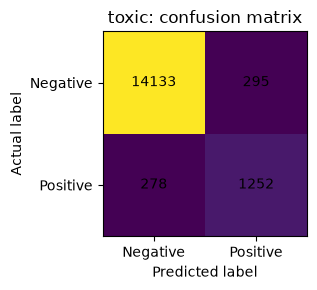

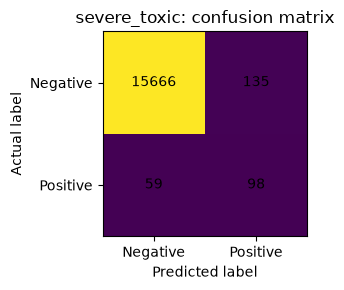

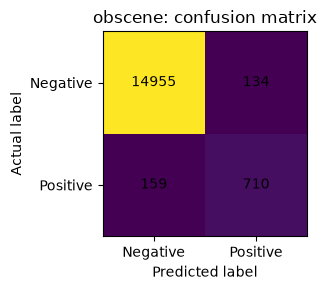

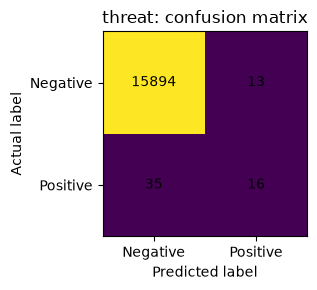

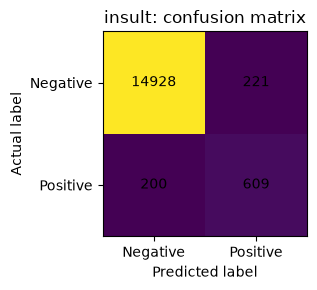

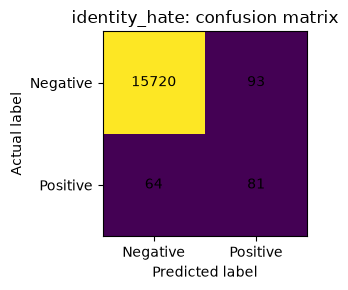

In [4]:
matrices = multilabel_confusion_matrix(Y_tox, Y_tox_pred)
for label, matrix in zip(LABELS, matrices):
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.imshow(matrix)
    ax.set_title(f"{label}: confusion matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], labels=["Negative", "Positive"])
    ax.set_yticks([0, 1], labels=["Negative", "Positive"])
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center")
    plt.tight_layout()
    plt.show()

## SMS spam model: overall metrics

In [5]:
X_spam = spam_bundle["features"].transform(spam_test["text"].fillna("").astype(str))
y_spam = spam_test["spam_label"].astype("string").str.lower().eq("spam").astype(int).to_numpy()
p_spam = spam_bundle["model"].predict_proba(X_spam)[:, 1]
spam_threshold = float(spam_bundle["threshold"])
y_spam_pred = (p_spam >= spam_threshold).astype(int)

spam_overall = pd.DataFrame([
    {"metric": "Accuracy", "value": accuracy_score(y_spam, y_spam_pred)},
    {"metric": "Precision (spam class)", "value": precision_score(y_spam, y_spam_pred, zero_division=0)},
    {"metric": "Recall (spam class)", "value": recall_score(y_spam, y_spam_pred, zero_division=0)},
    {"metric": "F1 (spam class)", "value": f1_score(y_spam, y_spam_pred, zero_division=0)},
    {"metric": "Macro F1", "value": f1_score(y_spam, y_spam_pred, average="macro", zero_division=0)},
    {"metric": "Weighted F1", "value": f1_score(y_spam, y_spam_pred, average="weighted", zero_division=0)},
    {"metric": "ROC-AUC", "value": roc_auc_score(y_spam, p_spam)},
    {"metric": "Decision threshold", "value": spam_threshold},
])
display(spam_overall.style.format({"value": "{:.4f}"}))
display(pd.DataFrame(classification_report(y_spam, y_spam_pred, labels=[0, 1], target_names=["ham", "spam"], output_dict=True, zero_division=0)).T)

,metric,value
0,Accuracy,0.9884
1,Precision (spam class),0.9531
2,Recall (spam class),0.9531
3,F1 (spam class),0.9531
4,Macro F1,0.9732
5,Weighted F1,0.9884
6,ROC-AUC,0.9983
7,Decision threshold,0.4100


,precision,recall,f1-score,support
ham,0.993363,0.993363,0.993363,452.000000
spam,0.953125,0.953125,0.953125,64.000000
accuracy,0.988372,0.988372,0.988372,0.988372
macro avg,0.973244,0.973244,0.973244,516.000000
weighted avg,0.988372,0.988372,0.988372,516.000000


## SMS confusion matrix

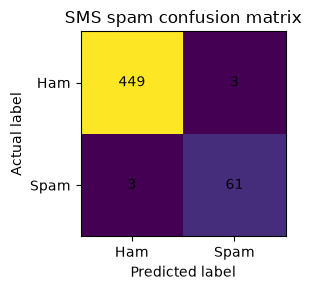

In [6]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_spam, y_spam_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(cm)
ax.set_title("SMS spam confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], labels=["Ham", "Spam"])
ax.set_yticks([0, 1], labels=["Ham", "Spam"])
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## Practical spam examples
These are diagnostic examples, not a substitute for the held-out test metrics. Review borderline messages and check false positives before deployment.

In [7]:
example_messages = [
    "Get some free money",
    "CONGRATULATIONS! You won a free prize! Click here now to claim your reward!",
    "Hey, are we still meeting at 6 pm?",
    "Thank you for helping our community organize the event.",
]
example_x = spam_bundle["features"].transform(example_messages)
example_p = spam_bundle["model"].predict_proba(example_x)[:, 1]
example_t = float(spam_bundle["threshold"])
display(pd.DataFrame({
    "text": example_messages,
    "spam_probability": example_p,
    "threshold": example_t,
    "predicted_label": np.where(example_p >= example_t, "spam", "ham"),
}))

,text,spam_probability,threshold,predicted_label
0,Get some free money,0.303406,0.41,ham
1,CONGRATULATIONS! You won a free prize! Click h...,0.971065,0.41,spam
2,"Hey, are we still meeting at 6 pm?",0.016902,0.41,ham
3,Thank you for helping our community organize t...,0.175410,0.41,ham
